In [26]:
from operator import index

import pandas as pd
import seaborn as sea
import matplotlib.pyplot as plt
import numpy as np

# um Warnungen zu ignorieren (auf eigene Gefahr!)
import warnings
warnings.filterwarnings("ignore")

## Lagemaße

In [27]:
# einladen des Pinguin-Datensatzes
penguins = pd.read_excel('./data/penguinsSmall.xlsx', index_col=0)
display(penguins.head(2))

,Individual ID,Species,Island,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex
0,N1A1,Adelie,Torgersen,2007-11-11,39.1,18.7,181,3750,MALE
1,N1A2,Adelie,Torgersen,2007-11-11,39.5,17.4,186,3800,FEMALE


## Frage 

Welchen Modus hat das Merkmal *Island* für die verschiedenen Pinguinarten? Benutze dabei die Methode [groupby](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html).

In [46]:
island_mode = penguins.groupby('Species')['Island'].apply(pd.Series.mode)
print(island_mode)

Species     
Adelie     0     Dream
Chinstrap  0     Dream
Gentoo     0    Biscoe
Name: Island, dtype: object


### Quantile

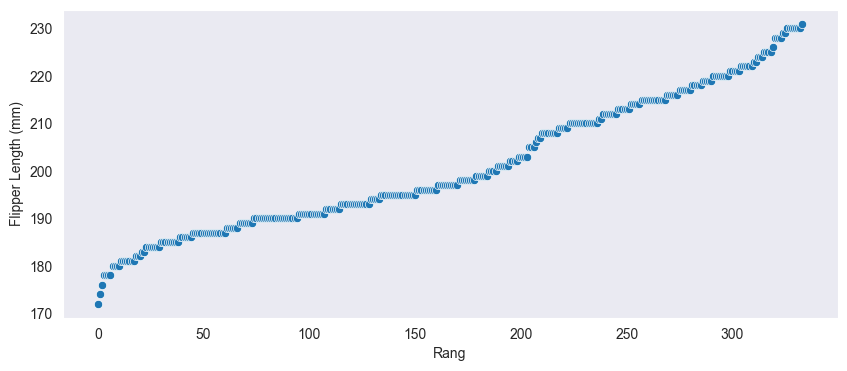

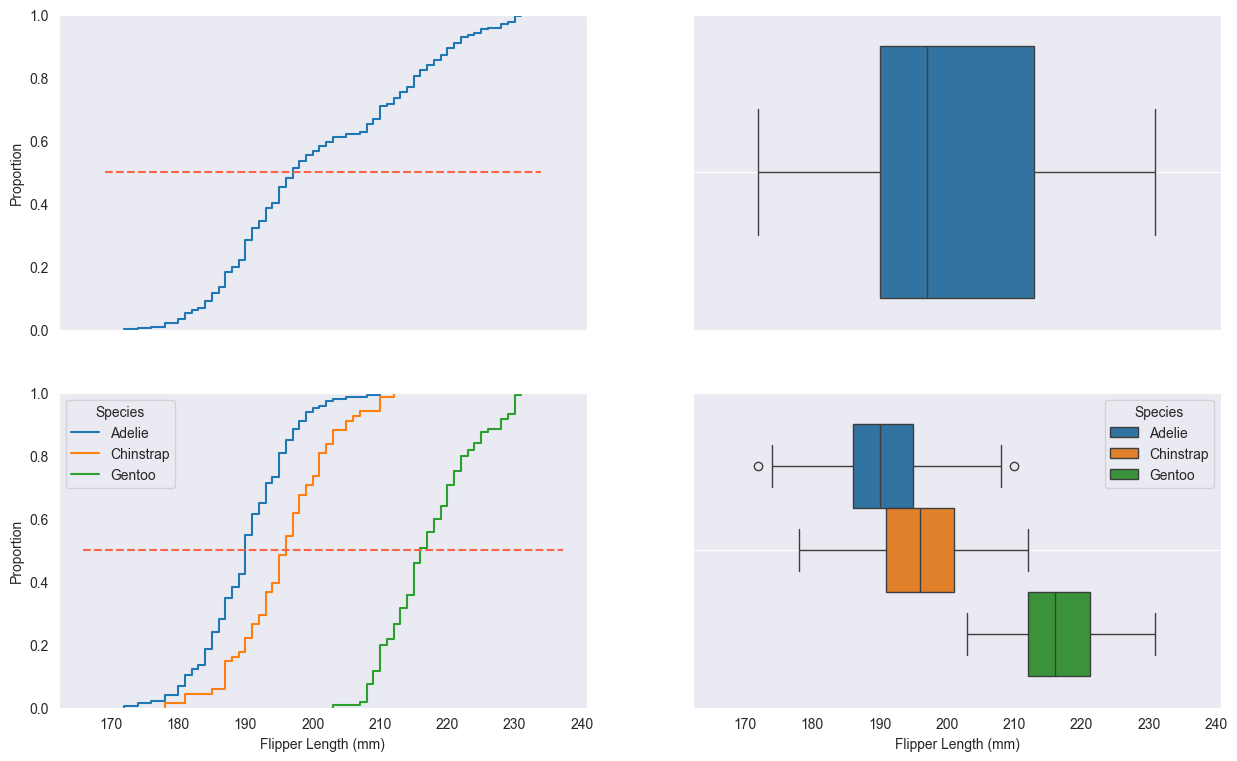

Quantile über alle Pinguine:
Quantil: 0.25, Wert:: 190.0000
Quantil: 0.5, Wert:: 197.0000
Quantil: 0.75, Wert:: 213.0000


In [29]:
# Benutzung des Merkmals Flipper Length
# Darstellung der Daten als geordnete Reihe mittels scatterplot

# scatterplot: https://seaborn.pydata.org/generated/seaborn.scatterplot.html

fig, ax = plt.subplots(1,1,figsize=(10,4))
sea.scatterplot(data=sorted(penguins['Flipper Length (mm)']), ax=ax)
ax.set_xlabel('Rang')
ax.set_ylabel('Flipper Length (mm)')
ax.grid()
plt.show()

# Darstellung der kumulierten Häufigkeit

# ecdfplot: https://seaborn.pydata.org/generated/seaborn.ecdfplot.html
# boxplot: https://seaborn.pydata.org/generated/seaborn.boxplot.html

fig, axs = plt.subplots(2,2,figsize=(15,9), sharex=True)
sea.ecdfplot(data=penguins, x='Flipper Length (mm)', ax=axs[0][0])
# hinzufügen der Linie p=0.5 (Median)
xlims = axs[0][0].get_xlim()
axs[0][0].plot(xlims, [0.5,0.5], linestyle='--', color='tomato')

sea.ecdfplot(data=penguins, x='Flipper Length (mm)', hue='Species', ax=axs[1][0], legend=True)
# hinzufügen der Linie p=0.5 (Median)
xlims = axs[1][0].get_xlim()
axs[1][0].plot(xlims, [0.5,0.5], linestyle='--', color='tomato')

sea.boxplot(data=penguins, x='Flipper Length (mm)', ax=axs[0][1])
sea.boxplot(data=penguins, x='Flipper Length (mm)', hue='Species', ax=axs[1][1])
axs[0][0].grid()
axs[1][0].grid()
axs[0][1].grid()
axs[1][1].grid()
plt.show()

# Bestimmung der Werte
q = [0.25, 0.5, 0.75]
values = np.quantile(penguins['Flipper Length (mm)'], q, method='nearest')
print('Quantile über alle Pinguine:')
for i, qq in enumerate(q):
    print('Quantil: {0}, Wert:: {1:.4f}'.format(qq, values[i]))

## Frage

Bestimme folgende Lagemaße für das Merkmal *Body Mass* in Abhängigkeit der Pinguinart:
- Median
- Minimum und Maximum
- das 10%- und das 90%-Quantil
- Mittelwert

Erstelle zusätzlich die entsprechenden Boxplots und [Violinplots](https://seaborn.pydata.org/generated/seaborn.violinplot.html). Ist eine Unterscheidung der Pinguine anhand dieses Merkmals sinnvoll?

Species:  Adelie
Median:  3700.0
Minimum:  2850
Maximum:  4775
10% Quantil:  3150.0
90% Quantil:  4325.0
Mittelwert:  3706.1643835616437
Species:  Chinstrap
Median:  3700.0
Minimum:  2700
Maximum:  4800
10% Quantil:  3300.0
90% Quantil:  4195.000000000001
Mittelwert:  3733.0882352941176
Species:  Gentoo
Median:  5050.0
Minimum:  3950
Maximum:  6300
10% Quantil:  4400.0
90% Quantil:  5705.0
Mittelwert:  5090.625


<Axes: xlabel='Species', ylabel='Body Mass (g)'>

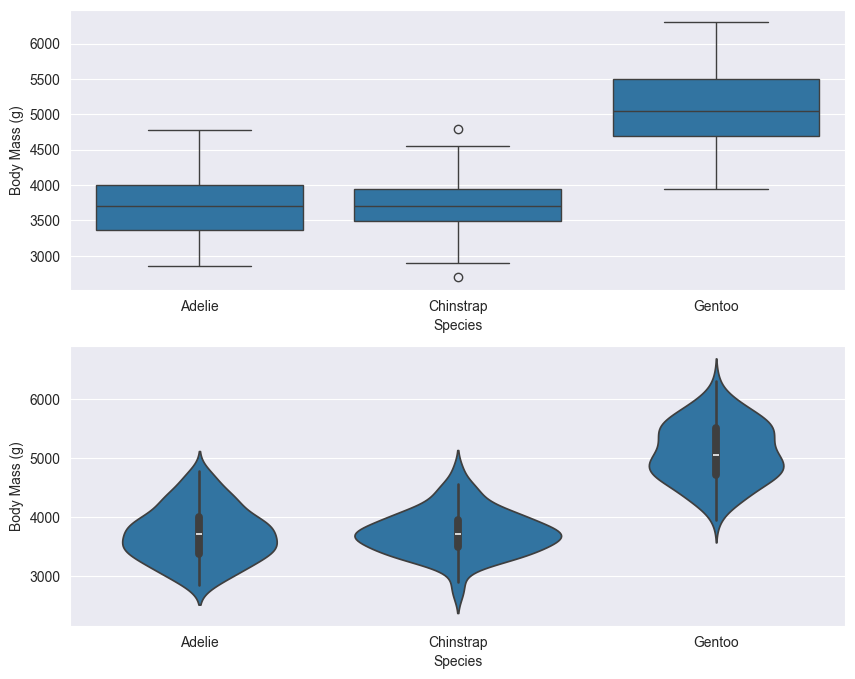

In [97]:

# Body Mass (g)
# species = penguins.groupby('Species')['Body Mass (g)']
# display(species.describe(exclude=['count', 'std'], percentiles=[0.1,0.9]))

for species, group in penguins.groupby("Species")['Body Mass (g)']:
    print("Species: ", species)
    print("Median: ", group.median())
    print("Minimum: ", group.min())
    print("Maximum: ", group.max())
    print("10% Quantil: ", group.quantile(0.1))
    print("90% Quantil: ", group.quantile(0.9))
    print("Mittelwert: ", group.mean())


fig, ax = plt.subplots(2,1,figsize=(10,8))
sea.boxplot(data=penguins, x='Species', y='Body Mass (g)', ax=ax[0])
sea.violinplot(data=penguins, x='Species', y='Body Mass (g)', ax=ax[1])

# Unterscheidung Sinnvoll? -> Naja, Gento kann von Adelie und Chinstrap gut mit dem Bodymass unterschieden werden.
# Adelie und Chinstrap aber nicht wirklich gut

## Geometrischer und Harmonischer Mittelwert

In [30]:
from scipy.stats import gmean, hmean

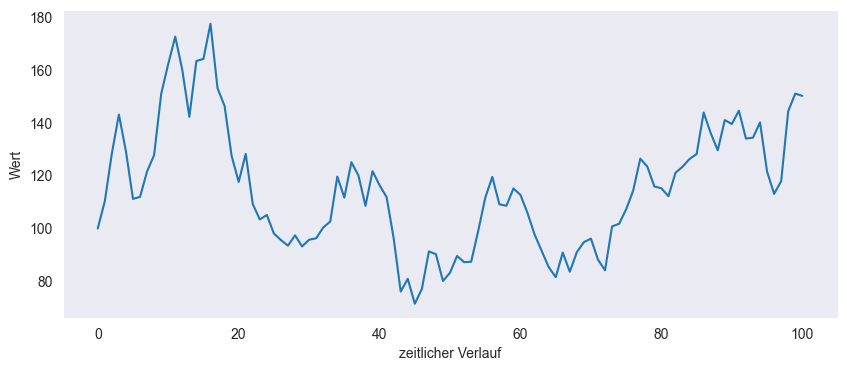

Wachstumsrate (arithmetrisch): 1.0079
Wachstumsrate (geometrisch): 1.0041


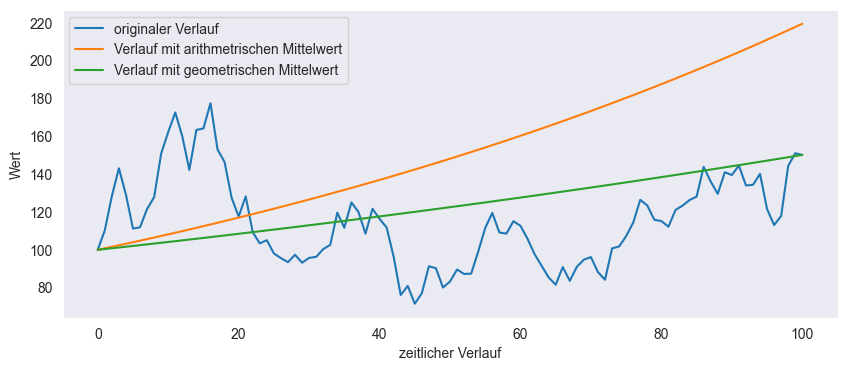

In [31]:
# Geometrischer Mittelwert für prozentuales Wachstum

# sequenz von Zufallszahlen als Wachstumsfaktoren
rng = np.random.default_rng(seed=2024) # seed erzeugt replizierbare Sequenzen
changes = rng.normal(loc=1, scale=0.1,size=100) # 100 Zufallszahlen basierend auf einer Normalverteilung
fig, ax = plt.subplots(1,1,figsize=(10,4))
werte = [100]  # Anfangswert ist 100
werte.extend(100*np.cumprod(changes)) # [100, 100*w1, 100*w1*w2, 100*w1*w2*w3 ...]
ax.plot(range(101),werte)
ax.grid()
ax.set_ylabel('Wert')
ax.set_xlabel('zeitlicher Verlauf')
plt.show()

# Bestimmung des artihmetrischen Mittelwertes des Wachstums
changes_mean = np.mean(changes)

# Bestimmung des geometrischen Mittelwertes
changes_gmean = gmean(changes)

print('Wachstumsrate (arithmetrisch): {0:.4f}'.format(changes_mean))
print('Wachstumsrate (geometrisch): {0:.4f}'.format(changes_gmean))


fig, ax = plt.subplots(1,1,figsize=(10,4))
ax.plot(range(101),werte, label='originaler Verlauf')
ax.plot(range(101),[100*changes_mean**i for i in range(101)], label='Verlauf mit arithmetrischen Mittelwert')
ax.plot(range(101),[100*changes_gmean**i for i in range(101)], label='Verlauf mit geometrischen Mittelwert')
ax.grid()
ax.set_ylabel('Wert')
ax.set_xlabel('zeitlicher Verlauf')
ax.legend()
plt.show()

In [32]:
# Beispiel Harmonischer Mittelwert

# gegeben sind folgende Daten 
strecke = [5,10,15,30,12] # Länge der einzelner Streckenabschnitte
v = [70,50,100,150,30] # km/h für die Streckenabschnitte

# gesucht durchschnittsgeschwindigkeit auf der gesamtstrecke
strecke_gesamt = sum(strecke)
# zeit pro streckenabschnitt
t = [strecke[i]/v[i] for i in range(5)]
zeit = sum(t)
print('tatsächlich zurückgelegte Strecke: {0:.2f}km'.format(strecke_gesamt))
print('tatsächlich benötigte Zeit: {0:.4f}h'.format(zeit))
print('Durchschnittsgeschwindigkeit: {0:.4f}km/h'.format(strecke_gesamt/zeit))

# mittelwerte der Geschwindigkeit
weights = [strecke[i]/strecke_gesamt for i in range(5)]
mean_har = hmean(v, weights=weights)
mean_ar = np.mean(v)
#mean_ar = np.sum([v[i]*weights[i] for i in range(5)])
print('\n')
print('Durchschnittsgeschwindigkeiten (arithmetrisch): {0:.4f}km/h'.format(mean_ar))
print('Durchschnittsgeschwindigkeiten (harmonisch): {0:.4f}km/h'.format(mean_har))

tatsächlich zurückgelegte Strecke: 72.00km
tatsächlich benötigte Zeit: 1.0214h
Durchschnittsgeschwindigkeit: 70.4895km/h


Durchschnittsgeschwindigkeiten (arithmetrisch): 80.0000km/h
Durchschnittsgeschwindigkeiten (harmonisch): 70.4895km/h


## Streumaße

In [59]:
# erstellung eines Dataframes
report = pd.DataFrame(index=['Adelie', 'Chinstrap', 'Gentoo'], columns=['Spannweite', 'Median', 'Iqr', 'Mean', 'Var'])
display(report)

,Spannweite,Median,Iqr,Mean,Var
Adelie,NaN,NaN,NaN,NaN,NaN
Chinstrap,NaN,NaN,NaN,NaN,NaN
Gentoo,NaN,NaN,NaN,NaN,NaN


## Frage

Befülle die entsprechenden Einträge im Dataframe *report* für das Merkmal *Culmen Length (mm)*.

In [83]:
#species = penguins.groupby('Species')['Culmen Length (mm)']

for species, group in penguins.groupby("Species")['Culmen Length (mm)']:
    spannweite = group.max() - group.min()
    median = group.median()
    iqr = group.quantile(0.75) - group.quantile(0.25)
    mean = group.mean()
    var = group.var()

    report.loc[species] = [spannweite, median, iqr, mean, var]

display(report)






,Spannweite,Median,Iqr,Mean,Var
Adelie,13.9,38.85,4.05,38.823973,7.089421
Chinstrap,17.1,49.55,4.725,48.833824,11.15063
Gentoo,18.7,47.35,4.3,47.5425,9.645321


### Standardisierte Werte

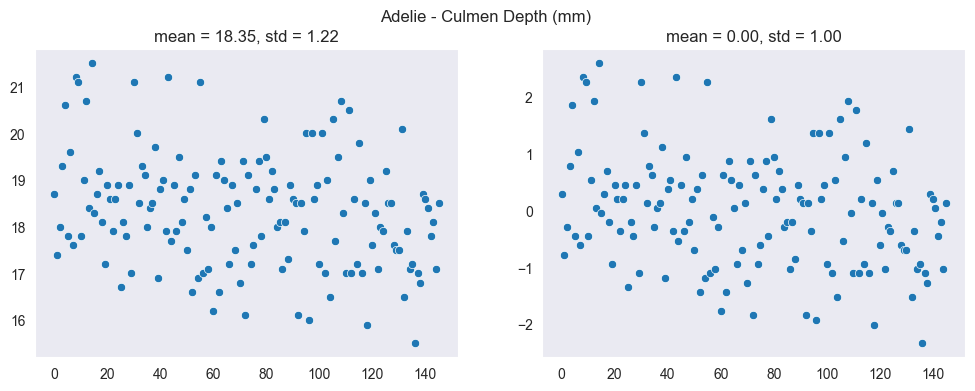

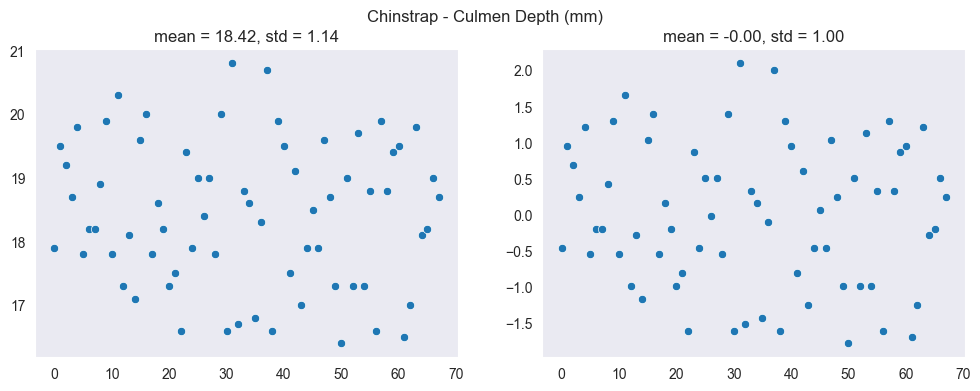

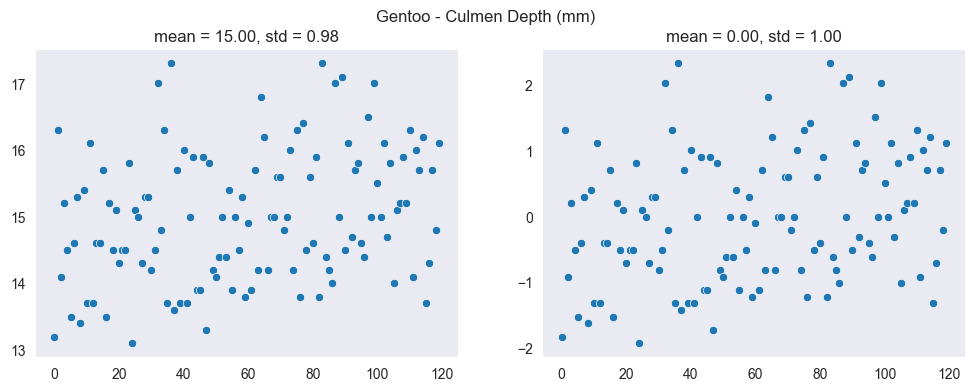

In [98]:
# Standardisierung der Daten am Beispiel der Culmen Depth
feature = 'Culmen Depth (mm)'
for pingu, data in penguins.groupby('Species'):
    # daten in ein numpy-array abspeichern
    orig = np.array(data[feature].values)
    mean = orig.mean()
    # Standardabweichung
    std = orig.std(ddof=1)
    # transformierte Daten
    transf = (orig - mean)/std
    fig, axs = plt.subplots(1,2,figsize=(12,4))
    sea.scatterplot(x=range(orig.shape[0]), y=orig, ax=axs[0])
    sea.scatterplot(x=range(transf.shape[0]), y=transf, ax=axs[1])
    axs[0].set_title('mean = {0:.2f}, std = {1:.2f}'.format(mean, std))
    axs[1].set_title('mean = {0:.2f}, std = {1:.2f}'.format(transf.mean(), transf.std(ddof=1)))
    axs[0].grid()
    axs[1].grid()
    fig.suptitle(pingu+' - '+feature)
    plt.show()
